# Separazione del dataset con SLP e MLP

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

dataset = [
    [0, 0, 1, 1], # x_1
    [0, 1, 0, 1], # x_2
    [0, 1, 1, 0]  # y
]

### Definizione della rete SLP

Il modello Single-Layer Perceptron (SLP) è poco efficace su alcuni tipi di problemi: è in grado di separare il dataset solo in modo lineare.

Vediamo una rappresentazione grafica di questo fatto, con input $\underline{x} \in \mathbb{R}^2$ ed output $y \in \mathbb{R}$.

In [2]:
def pre_activations(x, weights, bias):
    return np.dot(x, w) + b

def pre_activations2(x, weights, bias):
    return weights[0] * x[0] + weights[1] * x[1] + bias

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [3]:
def slp(x, weights, bias):
    return sigmoid(pre_activations2(x, weights, bias))

### Rappresentazione grafica di SLP

(array([10, 11, 11, 12, 12, 13, 13, 14, 14, 15, 15, 16, 16, 17, 17, 18, 18,
       19, 19, 20, 20, 21, 21, 22, 22, 23, 23, 24, 24, 25, 25, 26, 26, 27,
       27, 28, 28, 29, 29, 30, 30, 31, 31, 32, 32, 33, 33, 34, 34, 35, 35,
       36, 36, 37, 37, 38, 38, 39, 39, 40, 40, 41, 41, 42, 42, 43, 43, 44,
       44, 45, 45, 46, 46, 47, 47, 48, 48, 49, 49]), array([49, 48, 49, 47, 48, 46, 47, 45, 46, 44, 45, 43, 44, 42, 43, 41, 42,
       40, 41, 39, 40, 38, 39, 37, 38, 36, 37, 35, 36, 34, 35, 33, 34, 32,
       33, 31, 32, 30, 31, 29, 30, 28, 29, 27, 28, 26, 27, 25, 26, 24, 25,
       23, 24, 22, 23, 21, 22, 20, 21, 19, 20, 18, 19, 17, 18, 16, 17, 15,
       16, 14, 15, 13, 14, 12, 13, 11, 12, 10, 11]))


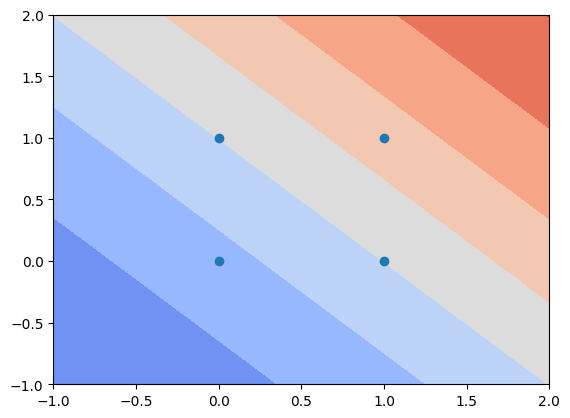

In [4]:
lin_x1 = np.linspace(-1, 2)
lin_x2 = np.linspace(-1, 2)

x = np.meshgrid(lin_x1, lin_x2)

ax = plt.axes()

W = np.array([0.6, 0.6])

results = slp(x, W, -1)

ax.contourf(*x, results, cmap=cm.coolwarm)

ax.scatter(*dataset[0:2])

threshold = 0.5
epsilon = 0.01

indexes = np.where(np.abs(results - threshold) <= epsilon)

print(indexes)

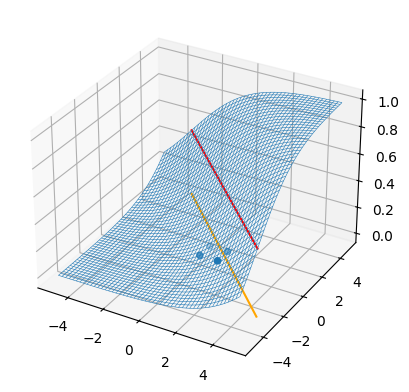

In [5]:
lin_x1 = np.linspace(-5, 5)
lin_x2 = np.linspace(-5, 5)

x = np.meshgrid(lin_x1, lin_x2)

ax2 = plt.axes(projection='3d')

results = slp(x, [0.6, 0.6], -1)

ax2.plot_wireframe(*x, results, linewidth=0.4)

ax2.scatter(*dataset[0:2])

threshold = 0.5
epsilon = 0.01

indexes = np.where(np.abs(results - threshold) <= epsilon)

ax2.plot(lin_x1[indexes[0]], lin_x2[indexes[1]], results[indexes], c="r")
ax2.plot(lin_x1[indexes[0]], lin_x2[indexes[1]], np.zeros(results[indexes].shape), c="orange")

### Definizione della rete MLP

Il modello Multi-Layer Perceptron (MLP) introduce una non linearità nella separazione del dataset, e per questo è sufficiente un solo strato nascosto.

Infatti, dal Teorema di approssimazione universale per reti neurali artificiali, sappiamo che un MLP con un solo strato nascosto è un buon approssimatore di $f \in \mathcal{C}^0(K)$ dove $K \subseteq \mathbb{R^N}$ è compatto.

In [ ]:
def mlp(x, weights1, weights2, bias1, bias2):
    return sigmoid(
        pre_activations(
            [
                sigmoid(pre_activations(x, weights1[0], bias1[0])),
                sigmoid(pre_activations(x, weights1[1], bias1[1]))
            ],
            weights2,
            bias2
            )
    ) # neurone 1 dello strato di output

### Rappresentazione grafica di MLP

In [ ]:
weights1 = [
    [0, 1],
    [1, 0]
]

weights2 = [1, 1]

bias1 = [3, 2]
bias2 = 1

ax2 = plt.axes(projection='3d')

results = mlp(x, weights1, weights2, bias1, bias2)

ax2.plot_surface(*x, results, cmap=cm.viridis)

threshold = 0.9
epsilon = 0.001

indexes = np.where(np.abs(results - threshold) <= epsilon)

ax2.plot(lin_x1[indexes[0]], lin_x2[indexes[1]], results[indexes], c="r")
